# 03 · Checks on the passive result

**The main result is in notebook 02 and doesn't change here.** Under the definitions chosen beforehand (500 km gap, 45 to 90°N, 70°W to 30°E), a passive balloon from Egilsstaðir or Keflavík spends fewer hours in the gap than one from Cambridge or New York.

This notebook asks two follow-up questions. **Both were added after seeing that result, and they're labelled that way wherever they appear.**

1. **Is the box edge at 30°E driving it?** Iceland balloons often drift towards the Barents and Kara Seas, east of 30°E. Here the box is widened to 90°E as a sensitivity check.
2. **Where do the gap-hours come from?** The main-box gap is split at 60°N into an **Atlantic part** (45 to 60°N) and an **Arctic part** (60 to 90°N). This doesn't change any definition. It only splits the same hours in two.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import balloon as b

SITES = {
    "Egilsstaðir":  (65.28, -14.40),
    "Keflavík":     (63.97, -22.60),
    "New York*":    (40.71, -74.01),
    "Cambridge MA": (42.36, -71.09),
    "Juneau":       (58.30, -134.42),
}
WINTERS = range(2013, 2022)
LEVELS = b.LEVELS
WIDE_LON_MAX = 90.0                     # sensitivity check: box widened to 90E
SPLIT_LAT = 60.0                        # Atlantic part below, Arctic part above

stations = b.active_stations()
main_dist = b.nearest_station_km_grid(stations)                       # 70W to 30E
wide_dist = b.nearest_station_km_grid(stations, lon_max=WIDE_LON_MAX)  # 70W to 90E
main_lats, _ = b.region_grid()

main_gap = main_dist > 500
atlantic_gap = main_gap & (main_lats[:, None] < SPLIT_LAT)
arctic_gap = main_gap & (main_lats[:, None] >= SPLIT_LAT)
wide_gaps = {km: wide_dist > km for km in [300, 500, 800]}
print("main-box gap cells:", main_gap.sum(), "=", atlantic_gap.sum(), "Atlantic +", arctic_gap.sum(), "Arctic")
print("wide-box gap cells at 500 km:", wide_gaps[500].sum())

main-box gap cells: 660 = 224 Atlantic + 436 Arctic
wide-box gap cells at 500 km: 852


## 1. What the wider box adds

The shaded areas are the 500 km gap. The part east of 30°E (the dashed line) is new in this check.

/opt/anaconda3/envs/windborne/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


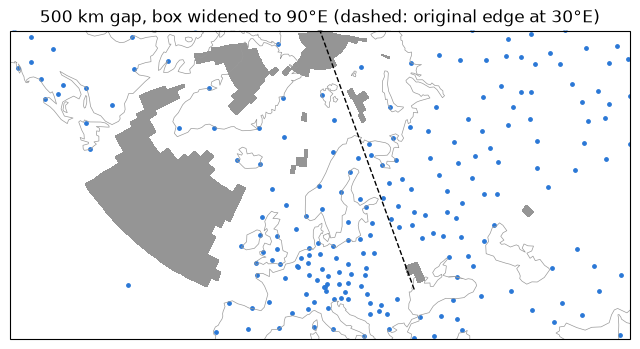

In [2]:
wide_lats, wide_lons = b.region_grid(WIDE_LON_MAX)
fig, ax = plt.subplots(figsize=(8, 6), subplot_kw=dict(projection=ccrs.NorthPolarStereo(central_longitude=10)))
ax.set_extent([-80, 100, 40, 90], crs=ccrs.PlateCarree())
ax.pcolormesh(wide_lons, wide_lats, np.where(wide_gaps[500], 1.0, np.nan),
              transform=ccrs.PlateCarree(), cmap="Greys", vmin=0, vmax=2, shading="auto")
ax.plot([30, 30], [45, 90], ls="--", color="black", lw=1, transform=ccrs.PlateCarree())
ax.scatter(stations.lon, stations.lat, s=6, color="#2a78d6", transform=ccrs.PlateCarree())
ax.coastlines(color="#999999", lw=0.5)
ax.set_title("500 km gap, box widened to 90°E (dashed: original edge at 30°E)")
plt.show()

## 2. Fly every launch again and count hours in each version of the gap

These are the same flights as notebook 02: the pole-safe integrator, launches every day at 00 UTC, and 21 days of flight.

In [3]:
def hours_in(lats, lons, mask, horizon_h, lon_max=b.GAP_LON_MAX):
    return b.in_gap(lats[1:horizon_h + 1], lons[1:horizon_h + 1], mask, lon_max).sum(axis=0)

rows = []
for winter in WINTERS:
    for li, lev in enumerate(LEVELS):
        lats, lons, names, launch = b.fly_winter(winter, SITES, li)
        rec = dict(winter=winter, level=lev, site=names, launch=launch)
        for hz, H in [("7d", 168), ("21d", 504)]:
            rec[f"main_{hz}"] = hours_in(lats, lons, main_gap, H)
            rec[f"atlantic_{hz}"] = hours_in(lats, lons, atlantic_gap, H)
            rec[f"arctic_{hz}"] = hours_in(lats, lons, arctic_gap, H)
            for km, m in wide_gaps.items():
                rec[f"wide{km}_{hz}"] = hours_in(lats, lons, m, H, WIDE_LON_MAX)
        rows.append(pd.DataFrame(rec))
checks = pd.concat(rows, ignore_index=True)
checks.to_csv("checks_runs.csv", index=False)

# sanity: the Atlantic and Arctic parts must add up to the main result exactly
assert (checks.atlantic_21d + checks.arctic_21d == checks.main_21d).all()
print(len(checks), "flights; Atlantic + Arctic = main for every flight")

12180 flights; Atlantic + Arctic = main for every flight


## 3. Check 1: does widening the box to 90°E change the ranking? *(added after seeing the result)*

Median gap-hours per launch. The `main` columns repeat notebook 02 for comparison. Ranks: 1 = most hours.

In [4]:
order = pd.MultiIndex.from_product([LEVELS, list(SITES)], names=["level", "site"])
cols = ["main_7d", "wide500_7d", "main_21d", "wide500_21d", "wide300_21d", "wide800_21d"]
wide_table = checks.groupby(["level", "site"])[cols].median().reindex(order)
display(wide_table)
print("Ranks (1 = most gap-hours):")
wide_table.groupby(level="level").rank(ascending=False, method="min").astype(int)

main_7d  wide500_7d  main_21d  wide500_21d  wide300_21d  \
level site                                                                    
850   Egilsstaðir       7.0         9.0      19.0         24.0         90.0   
      Keflavík         13.0        14.0      27.0         29.0        100.0   
      New York*        25.0        26.0      38.0         40.0         97.5   
      Cambridge MA     24.5        25.0      37.0         40.0         89.0   
      Juneau            0.0         0.0       0.0          0.0          0.0   
500   Egilsstaðir       1.0         2.0      12.0         14.0         55.0   
      Keflavík          2.0         4.0      14.0         16.5         59.0   
      New York*        14.0        15.0      18.0         20.0         41.0   
      Cambridge MA     16.0        16.0      20.0         20.5         48.0   
      Juneau           12.0        12.0      21.0         22.5         52.0   
250   Egilsstaðir       0.0         1.0      17.0         18.5         59.0   
      Keflavík          0.0         1.0      16.0         18.0         60.0   
      New York*         7.5         8.0      17.0         18.0         33.0   
      Cambridge MA      9.0         9.0      20.0         20.0         41.0   
      Juneau           12.0        12.5      23.0         24.0         57.0   

                    wide800_21d  
level site                       
850   Egilsstaðir           0.0  
      Keflavík              2.5  
      New York*            17.0  
      Cambridge MA         17.0  
      Juneau                0.0  
500   Egilsstaðir           0.0  
      Keflavík              0.0  
      New York*             8.0  
      Cambridge MA         10.0  
      Juneau                8.0  
250   Egilsstaðir           4.0  
      Keflavík              4.0  
      New York*             8.0  
      Cambridge MA          9.0  
      Juneau               10.0

Ranks (1 = most gap-hours):


main_7d  wide500_7d  main_21d  wide500_21d  wide300_21d  \
level site                                                                    
850   Egilsstaðir         4           4         4            4            3   
      Keflavík            3           3         3            3            1   
      New York*           1           1         1            1            2   
      Cambridge MA        2           2         2            1            4   
      Juneau              5           5         5            5            5   
500   Egilsstaðir         5           5         5            5            2   
      Keflavík            4           4         4            4            1   
      New York*           2           2         3            3            5   
      Cambridge MA        1           1         2            2            4   
      Juneau              3           3         1            1            3   
250   Egilsstaðir         4           4         3            3            2   
      Keflavík            4           4         5            4            1   
      New York*           3           3         3            4            5   
      Cambridge MA        2           2         2            2            4   
      Juneau              1           1         1            1            3   

                    wide800_21d  
level site                       
850   Egilsstaðir             4  
      Keflavík                3  
      New York*               1  
      Cambridge MA            1  
      Juneau                  4  
500   Egilsstaðir             4  
      Keflavík                4  
      New York*               2  
      Cambridge MA            1  
      Juneau                  2  
250   Egilsstaðir             4  
      Keflavík                4  
      New York*               3  
      Cambridge MA            2  
      Juneau                  1

## 4. Check 2: Atlantic part vs Arctic part *(a split of the main result, no new definition)*

These are **means**, not medians, because means add up: Atlantic + Arctic = total. The medians in notebook 02 are lower, because many launches get zero hours.

In [5]:
split = checks.groupby(["level", "site"])[["atlantic_7d", "arctic_7d", "main_7d",
                                           "atlantic_21d", "arctic_21d", "main_21d"]].mean().reindex(order)
# share of launches that reach the Arctic part at all within 21 days
split["share_reaching_arctic_21d"] = checks.assign(r=checks.arctic_21d > 0).groupby(["level", "site"]).r.mean().reindex(order)
split.round(2)

atlantic_7d  arctic_7d  main_7d  atlantic_21d  arctic_21d  \
level site                                                                      
850   Egilsstaðir         11.83       4.61    16.44         22.27        9.39   
      Keflavík            15.34       6.10    21.44         25.60       11.89   
      New York*           24.77       2.48    27.25         40.70        8.76   
      Cambridge MA        24.30       2.37    26.67         37.36        7.62   
      Juneau               0.11       0.13     0.23          9.17        2.74   
500   Egilsstaðir          2.21       4.92     7.14          9.10        8.71   
      Keflavík             4.26       5.48     9.74         11.42        9.12   
      New York*           14.18       2.48    16.66         18.98        4.80   
      Cambridge MA        15.52       3.31    18.83         20.64        6.03   
      Juneau              10.19       2.88    13.07         19.33        7.65   
250   Egilsstaðir          1.28       2.69     3.98         12.71        8.99   
      Keflavík             1.97       3.21     5.18         12.96        8.06   
      New York*            8.16       0.88     9.04         17.12        2.39   
      Cambridge MA         9.50       1.38    10.87         19.53        3.40   
      Juneau              11.23       2.52    13.75         20.96        5.95   

                    main_21d  share_reaching_arctic_21d  
level site                                               
850   Egilsstaðir      31.67                       0.71  
      Keflavík         37.48                       0.75  
      New York*        49.47                       0.53  
      Cambridge MA     44.98                       0.49  
      Juneau           11.91                       0.20  
500   Egilsstaðir      17.82                       0.59  
      Keflavík         20.54                       0.64  
      New York*        23.79                       0.34  
      Cambridge MA     26.66                       0.40  
      Juneau           26.98                       0.49  
250   Egilsstaðir      21.70                       0.69  
      Keflavík         21.02                       0.68  
      New York*        19.51                       0.33  
      Cambridge MA     22.93                       0.40  
      Juneau           26.91                       0.62

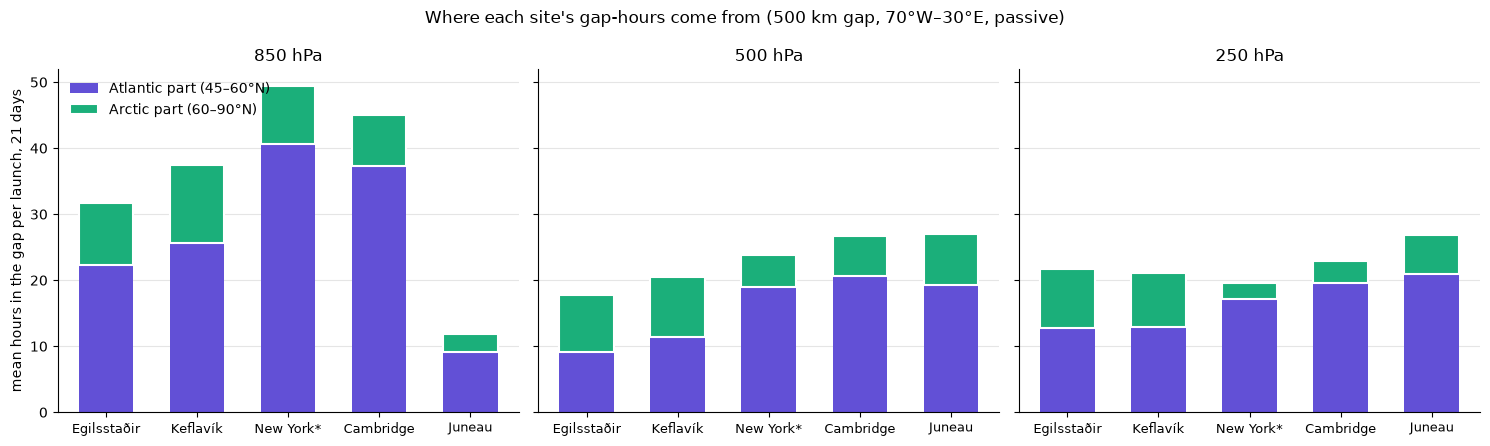

In [6]:
ATL, ARC = "#6250d6", "#1baf7a"     # two fixed colours: Atlantic part, Arctic part
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, lev in zip(axes, LEVELS):
    s = split.loc[lev]
    x = np.arange(len(SITES))
    ax.bar(x, s.atlantic_21d, color=ATL, width=0.6, label="Atlantic part (45–60°N)")
    ax.bar(x, s.arctic_21d, bottom=s.atlantic_21d, color=ARC, width=0.6,
           edgecolor="white", linewidth=1.5, label="Arctic part (60–90°N)")
    ax.set_xticks(x, [n.replace(" MA", "") for n in SITES], fontsize=9)
    ax.set_title(f"{lev} hPa")
    ax.grid(axis="y", color="#e5e5e5"); ax.set_axisbelow(True)
    for side in ["top", "right"]: ax.spines[side].set_visible(False)
axes[0].set_ylabel("mean hours in the gap per launch, 21 days")
axes[0].legend(frameon=False, loc="upper left")
plt.suptitle("Where each site's gap-hours come from (500 km gap, 70°W–30°E, passive)")
plt.tight_layout(); plt.show()

## What to read off this (Senan writes the findings)

1. Does widening the box to 90°E move Iceland up the ranking? By how much, and does it hold at 300 and 800 km?
2. Does Iceland lead on the **Arctic** part, even though it trails on the total?
3. If neither holds, the honest conclusion is that **per launch, passive Iceland balloons don't reach the gap more than US balloons**. The case for Iceland would then have to rest on other things, or on steering (notebook 04).